# Indian Startup Funding Analysis (2015–2025)

### Data Visualization Case Study

## Dataset Sources
| Dataset | Source | Coverage |
|---|---|---|
| Dataset 1 | Kaggle – *Indian Startup Funding* by Sudalai Rajkumar | 2015–2020 |
| Dataset 2 | Kaggle – *Indian Startup Funding Dataset (2020–2025)* by Vagdevi Titiksha G | 2020–2025 (Jan–Jun) |

The two files are merged in this notebook into one dataset of about 4,144 funding deals. Each record has a startup name, industry, sub-vertical, city, investors, investment type, amount in USD and date.

**Note:** Dataset 2 appears to be a sample, and its labels differ from Dataset 1. Because of this, charts mark the 2020 boundary and sector comparisons use only industries present in both datasets.

## Problem Statement
Indian startup funding has gone through boom and slowdown phases, but it is unclear how funding amounts, deal activity, sectors, cities and investors have changed over the last decade. This case study combines two public datasets and uses data visualization to identify these patterns while being open about data-quality limits.

## Analytical Objectives
1. Examine how total funding and deal count changed year by year (2015–2025).
2. Identify how the sector mix shifted over time.
3. Find which cities are the main funding hubs and how concentrated funding is.
4. Compare deal sizes across investment stages.
5. Identify which sectors attracted the most funding in which years.
6. Identify the most active investors and the composition of investment types.
7. Show how a misleading chart can distort these findings, and redesign it ethically.

## Tools Used
- **Matplotlib** – trend chart, misleading and corrected charts
- **Seaborn** – sector, city, stage, heatmap and investor charts
- **Plotly** – interactive scatter and treemap
- **Power BI** – interactive dashboard (separate `.pbix` file)

### Data Visualization Case Study

This case study analyzes Indian startup funding trends from 2015 to 2025 using two publicly available datasets.

The analysis focuses on:
- Year-wise funding trends
- Number of funding deals
- Industry-wise funding activity
- Investment types
- Geographic distribution of startups
- Investor participation

The objective is to identify major patterns and trends in the Indian startup ecosystem through data cleaning, exploratory data analysis, and visualization.

## 1. Import Libraries

The following Python libraries are used for data loading, preprocessing, analysis, and visualization.

In [1]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from matplotlib.colors import LogNorm

## 2. Load the Datasets

Two datasets are used in this analysis:

- **Dataset 1:** Indian startup funding data covering approximately 2015–2020.
- **Dataset 2:** Startup funding data covering 2020–2025.

The datasets are inspected individually before being standardized and combined.

In [3]:
df1 = pd.read_csv('../india-startup-funding-analysis/data/startup_funding.csv')
df2 = pd.read_csv('../india-startup-funding-analysis/data/indian_startup_funding_2020_2025_sample.csv')

## 3. Initial Dataset Exploration

Before cleaning the data, the structure, dimensions, data types, missing values, and duplicate records of both datasets are examined.

This step helps identify inconsistencies that need to be addressed before combining the datasets.

In [4]:
print("First Dataset Shape:", df1.shape)
print("Second Dataset Shape:", df2.shape)

print("\nFirst Dataset:")
display(df1.head())

print("\nSecond Dataset:")
display(df2.head())

First Dataset Shape: (3044, 10)
Second Dataset Shape: (1100, 8)

First Dataset:


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN



Second Dataset:


,Startup,Industry,SubVertical,City,Investors,InvestmentType,InvestmentAmount_USD,Date
0,Housejoy,EdTech,K12,Mumbai,Lightspeed India,Seed,199000,19-04-2023
1,Groww,Media,Streaming,Bengaluru,IFC,Seed,1668000,28-01-2025
2,Groww,Mobility,Ride Sharing,Hyderabad,"Nexus Venture Partners, Peak XV",Series B,38052000,14-03-2021
3,FarmBox,Consumer Electronics,Wearables,Gurugram,"Kalaari Capital, Y Combinator",Seed,455000,11-09-2023
4,Udaan,RealEstate,Rental Tech,Mumbai,Bessemer Venture Partners,Seed,89000,31-01-2024


In [5]:
print("FIRST DATASET INFORMATION")
df1.info()

print("\nSECOND DATASET INFORMATION")
df2.info()

FIRST DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Sr No              3044 non-null   int64
 1   Date dd/mm/yyyy    3044 non-null   str  
 2   Startup Name       3044 non-null   str  
 3   Industry Vertical  2873 non-null   str  
 4   SubVertical        2108 non-null   str  
 5   City  Location     2864 non-null   str  
 6   Investors Name     3020 non-null   str  
 7   InvestmentnType    3040 non-null   str  
 8   Amount in USD      2084 non-null   str  
 9   Remarks            419 non-null    str  
dtypes: int64(1), str(9)
memory usage: 237.9 KB

SECOND DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Startup               1100 non-null   str  
 1   Ind

In [6]:
print("Missing values in Dataset 1:")
display(df1.isnull().sum())

print("\nMissing values in Dataset 2:")
display(df2.isnull().sum())

Missing values in Dataset 1:


Sr No                   0
Date dd/mm/yyyy         0
Startup Name            0
Industry Vertical     171
SubVertical           936
City  Location        180
Investors Name         24
InvestmentnType         4
Amount in USD         960
Remarks              2625
dtype: int64


Missing values in Dataset 2:


Startup                 0
Industry                0
SubVertical             0
City                    0
Investors               0
InvestmentType          0
InvestmentAmount_USD    0
Date                    0
dtype: int64

In [7]:
print("Duplicate rows in Dataset 1:", df1.duplicated().sum())
print("Duplicate rows in Dataset 2:", df2.duplicated().sum())

Duplicate rows in Dataset 1: 0
Duplicate rows in Dataset 2: 0


## 4. Standardize Column Names

The two datasets contain similar information but use different column names.

The column names are standardized to establish a common structure for both datasets. Unnecessary columns are removed, and a `Data Source` column is added to identify the origin of each record.


In [8]:
df1 = df1.rename(columns={
    'Date dd/mm/yyyy': 'Date',
    'Startup Name': 'Startup',
    'Industry Vertical': 'Industry',
    'SubVertical': 'SubVertical',
    'City  Location': 'City',
    'Investors Name': 'Investors',
    'InvestmentnType': 'InvestmentType',
    'Amount in USD': 'InvestmentAmount_USD'
})

df2 = df2.rename(columns={
    'Startup': 'Startup',
    'Industry': 'Industry',
    'SubVertical': 'SubVertical',
    'City': 'City',
    'Investors': 'Investors',
    'InvestmentType': 'InvestmentType',
    'InvestmentAmount_USD': 'InvestmentAmount_USD',
    'Date': 'Date'
})

In [9]:
common_columns = [
    'Startup',
    'Industry',
    'SubVertical',
    'City',
    'Investors',
    'InvestmentType',
    'InvestmentAmount_USD',
    'Date'
]

df1 = df1[common_columns]
df2 = df2[common_columns]

In [10]:
df1['Data Source'] = '2015-2020 Dataset'
df2['Data Source'] = '2020-2025 Dataset'

In [11]:
display(df1.head())
display(df2.head())

,Startup,Industry,SubVertical,City,Investors,InvestmentType,InvestmentAmount_USD,Date,Data Source
0,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",09/01/2020,2015-2020 Dataset
1,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",13/01/2020,2015-2020 Dataset
2,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",09/01/2020,2015-2020 Dataset
3,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",02/01/2020,2015-2020 Dataset
4,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",02/01/2020,2015-2020 Dataset


,Startup,Industry,SubVertical,City,Investors,InvestmentType,InvestmentAmount_USD,Date,Data Source
0,Housejoy,EdTech,K12,Mumbai,Lightspeed India,Seed,199000,19-04-2023,2020-2025 Dataset
1,Groww,Media,Streaming,Bengaluru,IFC,Seed,1668000,28-01-2025,2020-2025 Dataset
2,Groww,Mobility,Ride Sharing,Hyderabad,"Nexus Venture Partners, Peak XV",Series B,38052000,14-03-2021,2020-2025 Dataset
3,FarmBox,Consumer Electronics,Wearables,Gurugram,"Kalaari Capital, Y Combinator",Seed,455000,11-09-2023,2020-2025 Dataset
4,Udaan,RealEstate,Rental Tech,Mumbai,Bessemer Venture Partners,Seed,89000,31-01-2024,2020-2025 Dataset


## 5. Clean and Standardize Dates

The date columns are converted into a consistent datetime format to support time-based analysis.

The initial inspection identifies incorrectly formatted dates in the first dataset. These values are corrected before converting the columns into datetime objects.

The cleaned dates are validated to ensure that both datasets can be analyzed consistently.


In [12]:
df1['Date'] = pd.to_datetime(
    df1['Date'],
    dayfirst=True,
    errors='coerce'
)

df2['Date'] = pd.to_datetime(
    df2['Date'],
    dayfirst=True,
    errors='coerce'
)

In [13]:
print("Unparseable dates in Dataset 1:",
      df1['Date'].isna().sum())

print("Unparseable dates in Dataset 2:",
      df2['Date'].isna().sum())

Unparseable dates in Dataset 1: 8
Unparseable dates in Dataset 2: 0


In [14]:
bad_dates = df1[df1['Date'].isna()]

display(
    bad_dates[
        ['Startup', 'Date', 'InvestmentAmount_USD', 'Industry']
    ]
)

,Startup,Date,InvestmentAmount_USD,Industry
192,Loan Tap,NaT,"62,50,000",Consumer Internet
2571,HandyHome,NaT,"6,30,000",Hyperlocal Electronics repair Service
2606,\\xc2\\xa0Infinity Assurance,NaT,"\\xc2\\xa0600,000",\\xc2\\xa0Warranty Programs Service Administra...
2775,Mobiefit,NaT,NaN,Mobile Fitness App
2776,Plancess,NaT,"20,00,000",Online Education Platform
2831,The Porter,NaT,"5,00,000",Logistics Tech
3011,Wishberry,NaT,"6,50,000",NaN
3029,Corporate360,NaT,"2,00,000",NaN


In [15]:
# Get the original date values from the CSV
original_df1 = pd.read_csv("../india-startup-funding-analysis/data/startup_funding.csv")

bad_rows = df1['Date'].isna()

display(
    original_df1.loc[
        bad_rows,
        ['Startup Name', 'Date dd/mm/yyyy']
    ]
)

,Startup Name,Date dd/mm/yyyy
192,Loan Tap,05/072018
2571,HandyHome,01/07/015
2606,\\xc2\\xa0Infinity Assurance,\\xc2\\xa010/7/2015
2775,Mobiefit,12/05.2015
2776,Plancess,12/05.2015
2831,The Porter,13/04.2015
3011,Wishberry,15/01.2015
3029,Corporate360,22/01//2015


In [16]:
# Reload the original dataset
df1 = pd.read_csv("../india-startup-funding-analysis/data/startup_funding.csv")

# Rename columns
df1 = df1.rename(columns={
    'Date dd/mm/yyyy': 'Date',
    'Startup Name': 'Startup',
    'Industry Vertical': 'Industry',
    'SubVertical': 'SubVertical',
    'City  Location': 'City',
    'Investors Name': 'Investors',
    'InvestmentnType': 'InvestmentType',
    'Amount in USD': 'InvestmentAmount_USD'
})

# Keep common columns
common_columns = [
    'Startup', 'Industry', 'SubVertical', 'City',
    'Investors', 'InvestmentType', 'InvestmentAmount_USD', 'Date'
]

df1 = df1[common_columns]

# Add source
df1['Data Source'] = '2015-2020 Dataset'


# ---------- FIX DATES ----------

# Keep dates as text first
df1['Date'] = df1['Date'].astype(str).str.strip()

# Remove encoding artifact
df1['Date'] = df1['Date'].str.replace(
    r'\\xc2\\xa0', '', regex=True
)

# Fix the 8 malformed dates
date_fixes = {
    '05/072018': '05/07/2018',
    '01/07/015': '01/07/2015',
    '10/7/2015': '10/07/2015',
    '12/05.2015': '12/05/2015',
    '13/04.2015': '13/04/2015',
    '15/01.2015': '15/01/2015',
    '22/01//2015': '22/01/2015'
}

df1['Date'] = df1['Date'].replace(date_fixes)

# Convert to proper datetime
df1['Date'] = pd.to_datetime(
    df1['Date'],
    dayfirst=True,
    errors='coerce'
)

print("Missing dates after cleaning:", df1['Date'].isna().sum())

Missing dates after cleaning: 1


In [17]:
# Fix the remaining problematic date
df1.loc[df1['Startup'].str.contains('Infinity Assurance', na=False), 'Date'] = '10/07/2015'

# Convert again to datetime
df1['Date'] = pd.to_datetime(
    df1['Date'],
    dayfirst=True,
    errors='coerce'
)

print("Missing dates after cleaning:", df1['Date'].isna().sum())

Missing dates after cleaning: 0


In [18]:
print("Dataset 1 missing dates:", df1['Date'].isna().sum())
print("Dataset 2 missing dates:", df2['Date'].isna().sum())

print("\nDate data types:")
print(df1['Date'].dtype)
print(df2['Date'].dtype)

Dataset 1 missing dates: 0
Dataset 2 missing dates: 0

Date data types:
datetime64[us]
datetime64[us]


## 6. Clean Investment Amounts

The investment amount columns contain different data formats across the two datasets.

The following preprocessing steps are performed:

* Remove commas and unnecessary whitespace from investment amounts.
* Convert investment amounts into numeric values.
* Identify missing investment amounts after conversion.

Missing amounts are retained as missing values because undisclosed funding amounts should not be treated as zero.


In [19]:
print("Dataset 1 - Funding Amount Examples:")
display(df1['InvestmentAmount_USD'].head(20))

print("\nDataset 1 - Unique amount formats:")
display(df1['InvestmentAmount_USD'].dropna().head(20))

Dataset 1 - Funding Amount Examples:


0     20,00,00,000
1        80,48,394
2      1,83,58,860
3        30,00,000
4        18,00,000
5        90,00,000
6     15,00,00,000
7        60,00,000
8      7,00,00,000
9      5,00,00,000
10     2,00,00,000
11     1,20,00,000
12     3,00,00,000
13       59,00,000
14       20,00,000
15     5,00,00,000
16    23,10,00,000
17    15,00,00,000
18        4,86,000
19       15,00,000
Name: InvestmentAmount_USD, dtype: str


Dataset 1 - Unique amount formats:


0     20,00,00,000
1        80,48,394
2      1,83,58,860
3        30,00,000
4        18,00,000
5        90,00,000
6     15,00,00,000
7        60,00,000
8      7,00,00,000
9      5,00,00,000
10     2,00,00,000
11     1,20,00,000
12     3,00,00,000
13       59,00,000
14       20,00,000
15     5,00,00,000
16    23,10,00,000
17    15,00,00,000
18        4,86,000
19       15,00,000
Name: InvestmentAmount_USD, dtype: str

In [20]:
print(
    df1['InvestmentAmount_USD']
    .dropna()
    .astype(str)
    .value_counts()
    .head(20)
)

InvestmentAmount_USD
10,00,000      165
5,00,000       108
20,00,000       69
30,00,000       66
50,00,000       66
1,00,00,000     60
1,00,000        57
1,50,000        45
2,00,000        44
2,50,000        41
60,00,000       40
1,50,00,000     39
15,00,000       37
40,00,000       35
3,00,000        31
25,00,000       25
5,00,00,000     24
6,00,000        23
2,00,00,000     21
4,00,000        21
Name: count, dtype: int64


In [21]:
df1['InvestmentAmount_USD'] = (
    df1['InvestmentAmount_USD']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
)

In [22]:
df1['InvestmentAmount_USD'] = pd.to_numeric(
    df1['InvestmentAmount_USD'],
    errors='coerce'
)

df2['InvestmentAmount_USD'] = pd.to_numeric(
    df2['InvestmentAmount_USD'],
    errors='coerce'
)

print("Dataset 1 amount type:")
print(df1['InvestmentAmount_USD'].dtype)

print("\nDataset 2 amount type:")
print(df2['InvestmentAmount_USD'].dtype)

print("\nMissing amounts:")
print("Dataset 1:", df1['InvestmentAmount_USD'].isna().sum())
print("Dataset 2:", df2['InvestmentAmount_USD'].isna().sum())

Dataset 1 amount type:
float64

Dataset 2 amount type:
int64

Missing amounts:
Dataset 1: 979
Dataset 2: 0


## 7. Handle Missing Values

Missing values are examined to determine which columns require preprocessing.

Missing values in categorical columns are replaced with `Not specified` to preserve records for further analysis.

Missing investment amounts are retained because their actual values cannot be determined from the available data.


In [23]:
text_columns = [
    'Startup',
    'Industry',
    'SubVertical',
    'City',
    'Investors',
    'InvestmentType'
]

for col in text_columns:
    df1[col] = df1[col].astype('string').str.strip()
    df2[col] = df2[col].astype('string').str.strip()

In [24]:
for col in text_columns:
    df1[col] = df1[col].fillna('Not specified')
    df2[col] = df2[col].fillna('Not specified')

In [25]:
print("Dataset 1 missing values:")
print(df1.isna().sum())

print("\nDataset 2 missing values:")
print(df2.isna().sum())

Dataset 1 missing values:
Startup                   0
Industry                  0
SubVertical               0
City                      0
Investors                 0
InvestmentType            0
InvestmentAmount_USD    979
Date                      0
Data Source               0
dtype: int64

Dataset 2 missing values:
Startup                 0
Industry                0
SubVertical             0
City                    0
Investors               0
InvestmentType          0
InvestmentAmount_USD    0
Date                    0
Data Source             0
dtype: int64


## 8. Combine the Datasets

After standardizing the column names and cleaning the data, both datasets are combined into a single DataFrame using Pandas.

The `Data Source` column is retained to distinguish records from the two original datasets.

The combined dataset is inspected to verify its dimensions, data types, and remaining missing values.


In [26]:
df = pd.concat(
    [df1, df2],
    ignore_index=True
)

print("\nCombined Dataset Shape:", df.shape)

display(df.head())
display(df.tail())

print("\nFinal Dataset Information:")
df.info()

print("\nFinal Missing Values:")
display(df.isnull().sum())


Combined Dataset Shape: (4144, 9)


,Startup,Industry,SubVertical,City,Investors,InvestmentType,InvestmentAmount_USD,Date,Data Source
0,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,200000000.0,2020-01-09,2015-2020 Dataset
1,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,8048394.0,2020-01-13,2015-2020 Dataset
2,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,18358860.0,2020-01-09,2015-2020 Dataset
3,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,3000000.0,2020-01-02,2015-2020 Dataset
4,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,1800000.0,2020-01-02,2015-2020 Dataset


,Startup,Industry,SubVertical,City,Investors,InvestmentType,InvestmentAmount_USD,Date,Data Source
4139,HealthAnalytics_1095,FoodTech,Food Delivery,Pune,"Lightspeed India, Mirae Asset, Prosus Ventures",Angel,8000.0,2020-11-24,2020-2025 Dataset
4140,NextStack,Consumer Electronics,Smart Home,Kolkata,SoftBank Vision Fund,Series C,36336000.0,2024-01-02,2020-2025 Dataset
4141,FoodFit,Media,Content,Delhi,Nexus Venture Partners,Seed,99000.0,2020-08-08,2020-2025 Dataset
4142,FoodSolutions,Retail,Fashion,Gurugram,Info Edge,Seed,887000.0,2024-08-26,2020-2025 Dataset
4143,MediSpace,Logistics,Supply Chain,Kolkata,Ribbit Capital,Seed,182000.0,2022-05-28,2020-2025 Dataset



Final Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4144 entries, 0 to 4143
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Startup               4144 non-null   string        
 1   Industry              4144 non-null   string        
 2   SubVertical           4144 non-null   string        
 3   City                  4144 non-null   string        
 4   Investors             4144 non-null   string        
 5   InvestmentType        4144 non-null   string        
 6   InvestmentAmount_USD  3165 non-null   float64       
 7   Date                  4144 non-null   datetime64[us]
 8   Data Source           4144 non-null   str           
dtypes: datetime64[us](1), float64(1), str(1), string(6)
memory usage: 291.5 KB

Final Missing Values:


Startup                   0
Industry                  0
SubVertical               0
City                      0
Investors                 0
InvestmentType            0
InvestmentAmount_USD    979
Date                      0
Data Source               0
dtype: int64

## 9. Feature Extraction and Final Validation

The year and month are extracted from the cleaned date column to support time-based analysis.

The final dataset is validated by examining:

* Total number of records and columns
* Remaining missing values
* Date range covered by the datasets
* Years represented in the analysis

These steps prepare the dataset for exploratory data analysis and visualization.


In [27]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

In [28]:
display(
    df[['Date', 'Year', 'Month']].head()
)

,Date,Year,Month
0,2020-01-09,2020,1
1,2020-01-13,2020,1
2,2020-01-09,2020,1
3,2020-01-02,2020,1
4,2020-01-02,2020,1


In [29]:
print("Final Dataset Shape:", df.shape)

print("\nFinal Missing Values:")
display(df.isnull().sum())

print("\nDate Range:")
print("From:", df['Date'].min())
print("To:", df['Date'].max())

print("\nYears:")
print(sorted(df['Year'].unique()))

Final Dataset Shape: (4144, 11)

Final Missing Values:


Startup                   0
Industry                  0
SubVertical               0
City                      0
Investors                 0
InvestmentType            0
InvestmentAmount_USD    979
Date                      0
Data Source               0
Year                      0
Month                     0
dtype: int64


Date Range:
From: 2015-01-02 00:00:00
To: 2025-06-30 00:00:00

Years:
[np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


## 10. Visualization Setup

Before plotting, a few helper columns are prepared:

- **`Amount_M`** – deal amount in USD millions (easier to read on charts).
- **`City_Clean`, `Industry_Clean`, `Stage`** – standardized labels, because the raw data spells the same city, industry or round in several ways (e.g. *Bangalore / Bengaluru*, *E-Tech / EdTech*, *SeriesA / Series A*).
- **`funded`** – only the deals with a disclosed amount. It is used for every chart about **money**, while the full `df` is used for **deal counts**. Undisclosed amounts are never treated as zero.
- **Data correction:** Rapido's 2019 Series B was recorded as USD 3.9 billion, a rupee figure entered in the USD column. It was corrected to USD 54.9M.

In [30]:
import re
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

def show(text):
    display(Markdown(text))

def strip_junk(s):
    """Remove junk characters and extra spaces."""
    return (s.astype(str)
              .str.replace(r"\\x[0-9a-fA-F]{2}", "", regex=True)
              .str.strip())

# ---------- Amount in USD millions ----------
mask = (df["Startup"].str.contains("Rapido", na=False)
        & (df["Year"] == 2019) & (df["InvestmentAmount_USD"] == 3.9e9))
df.loc[mask, "InvestmentAmount_USD"] = 54.9e6
print("Rows corrected:", mask.sum())
df["Amount_M"] = df["InvestmentAmount_USD"] / 1e6

# ---------- City ----------
city_map = {
    "Bangalore": "Bengaluru", "Bengaluru": "Bengaluru",
    "Gurgaon": "Delhi NCR", "Gurugram": "Delhi NCR", "New Delhi": "Delhi NCR",
    "Delhi": "Delhi NCR", "Noida": "Delhi NCR", "Greater Noida": "Delhi NCR",
    "Ghaziabad": "Delhi NCR", "Faridabad": "Delhi NCR",
    "Bombay": "Mumbai", "Navi Mumbai": "Mumbai", "Thane": "Mumbai",
    "Madras": "Chennai","Kormangala": "Bengaluru", "Koramangala": "Bengaluru"
}
city = strip_junk(df["City"]).str.split(r"[/,]", regex=True).str[0].str.strip().str.title()
df["City_Clean"] = city.replace(city_map)

# ---------- Industry ----------
industry_rules = [
    ("e-commerce", "E-commerce"), ("ecommerce", "E-commerce"),
    ("fintech", "FinTech"), ("fin-tech", "FinTech"), ("financ", "FinTech"),
    ("edtech", "EdTech"), ("ed-tech", "EdTech"), ("e-tech", "EdTech"), ("educat", "EdTech"),
    ("health", "HealthTech"), ("saas", "SaaS"), ("software", "SaaS"),
    ("consumer internet", "Consumer Internet"),
    ("logistic", "Logistics"), ("transport", "Mobility"), ("mobility", "Mobility"),
    ("food", "FoodTech"), ("agri", "AgriTech"), ("media", "Media"),
]
def clean_industry(x):
    t = x.lower()
    if t in ("it", "information technology"):
        return "Technology"
    for key, label in industry_rules:
        if key in t:
            return label
    return x.title()

df["Industry_Clean"] = strip_junk(df["Industry"]).map(clean_industry)

# ---------- Investment stage ----------
def clean_stage(x):
    k = re.sub(r"[^a-z]", "", x.lower())
    if "preseries" in k:                  return "Pre-Series A"
    if "seriesa" in k:                    return "Series A"
    if "seriesb" in k:                    return "Series B"
    if "seriesc" in k:                    return "Series C"
    if re.search(r"series[d-h]", k):      return "Series D+"
    if "seed" in k and "angel" in k:      return "Seed/Angel"
    if "seed" in k:                       return "Seed"
    if "angel" in k:                      return "Angel"
    if "privateequity" in k:              return "Private Equity"
    if "growth" in k:                     return "Growth"
    if "debt" in k:                       return "Debt"
    if "venture" in k:                    return "Venture"
    return x.title()

df["Stage"] = strip_junk(df["InvestmentType"]).map(clean_stage)

# ---------- Rows used for amount-based charts ----------
UNKNOWN = ["Not Specified", "Nan", "", "Other",
           "India", "California", "Menlo Park", "San Francisco", "Tulangan",
           "San Jose", "Santa Monica", "Singapore", "New York", "Palo Alto"]
funded = df[df["InvestmentAmount_USD"].notna() & (df["InvestmentAmount_USD"] > 0)].copy()

print(f"All deals: {len(df):,} | Deals with a disclosed amount: {len(funded):,} "
      f"({len(funded)/len(df):.0%})")
display(df["Industry_Clean"].value_counts().head(15))

Rows corrected: 1
All deals: 4,144 | Deals with a disclosed amount: 3,165 (76%)


Industry_Clean
Consumer Internet       942
Technology              489
E-commerce              422
HealthTech              184
Not Specified           171
FinTech                 165
FoodTech                158
EdTech                  142
Logistics               124
Mobility                 97
Media                    95
SaaS                     94
Retail                   90
Consumer Electronics     87
AgriTech                 85
Name: count, dtype: int64

## 11. Visualization 1 – Year-wise Funding Trend (Matplotlib)

**Chart type:** line chart (total funding) combined with bars (number of deals) on a secondary axis.
**Purpose:** show the overall temporal trend from 2015 to 2025 and where growth and slowdown occurred.
**Design choices:**
- Funding and deal count are shown together, because ~1 in 3 deals in the first dataset has no disclosed amount; deal count is a more complete measure of activity.
- A dashed line marks 2020, where the two datasets overlap, so the reader knows the source changes there.
- 2025 covers only January–June, so it is a partial year.

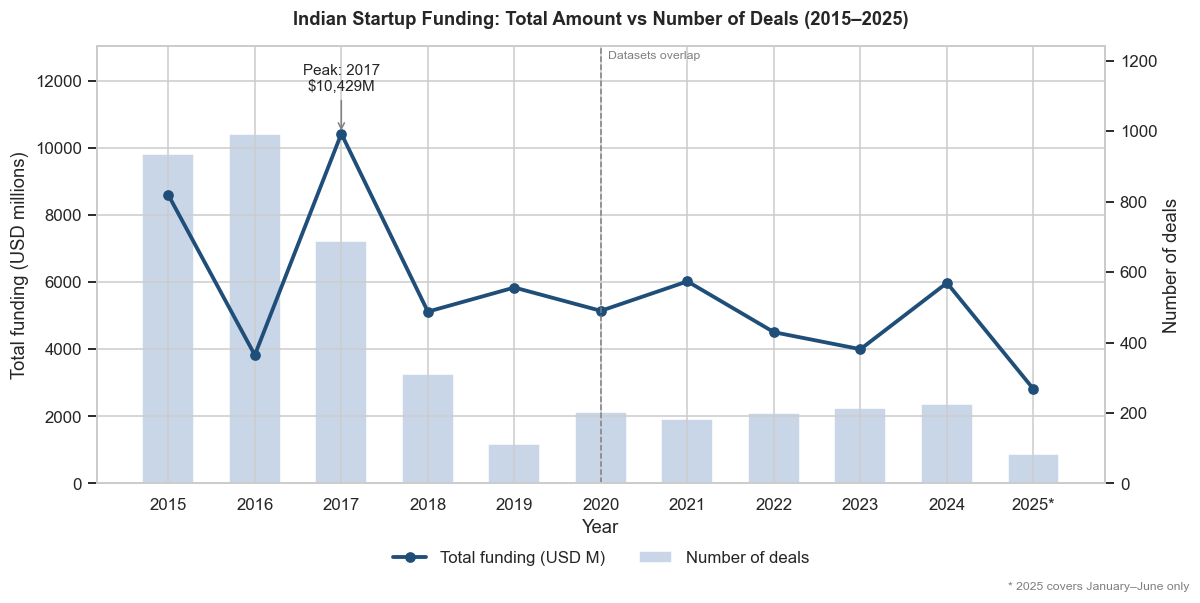

,Deals,Funding_M
Year,,
2015,936,8601.2
2016,993,3828.1
2017,687,10429.3
2018,310,5122.4
2019,111,5841.5
2020,202,5146.9
2021,183,6024.9
2022,200,4509.7
2023,213,4002.0


In [31]:
yearly = (df.groupby("Year").size().rename("Deals").to_frame()
            .join(funded.groupby("Year")["Amount_M"].sum().rename("Funding_M"))
            .fillna(0))

fig, ax1 = plt.subplots(figsize=(11, 5.5))
ax2 = ax1.twinx()

# Bars: deal count (secondary axis, drawn behind)
ax2.bar(yearly.index, yearly["Deals"], color="#c9d6e8", width=0.6, label="Number of deals")
ax2.set_ylabel("Number of deals")
ax2.grid(False)

# Line: total funding (primary axis, drawn on top)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
ax1.plot(yearly.index, yearly["Funding_M"], color="#1f4e79", marker="o",
         linewidth=2.5, label="Total funding (USD M)")
ax1.set_ylabel("Total funding (USD millions)")
ax1.set_xlabel("Year")

# Zero baseline on both axes (honest scaling) + headroom for labels
ax1.set_ylim(0, yearly["Funding_M"].max() * 1.25)
ax2.set_ylim(0, yearly["Deals"].max() * 1.25)

# Annotate the peak funding year
peak_year = yearly["Funding_M"].idxmax()
peak_val = yearly["Funding_M"].max()
ax1.annotate(f"Peak: {peak_year}\n${peak_val:,.0f}M", xy=(peak_year, peak_val),
             xytext=(0, 28), textcoords="offset points", ha="center", fontsize=10,
             arrowprops=dict(arrowstyle="->", color="gray"))

# Dataset boundary + partial-year marker
ax1.axvline(2020, color="gray", linestyle="--", linewidth=1)
ax1.text(2020.08, ax1.get_ylim()[1] * 0.99, "Datasets overlap", fontsize=8, color="gray", va="top")
labels = [f"{y}*" if y == yearly.index.max() else str(y) for y in yearly.index]
ax1.set_xticks(yearly.index)
ax1.set_xticklabels(labels)

ax1.set_title("Indian Startup Funding: Total Amount vs Number of Deals (2015–2025)", pad=14)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
fig.text(0.99, 0.01, "* 2025 covers January–June only", ha="right", fontsize=8, color="gray")
plt.tight_layout()
plt.show()
display(yearly.round(1))

### Insight 1 – Funding trend

- **Funding is volatile rather than steadily growing.** Total funding was USD 8,601M in 2015, fell to USD 3,828M in 2016 (-55.5%), and reached its overall peak of **USD 10,429M in 2017** (+172.4%). It then dropped to USD 5,122M in 2018 (-50.9%) and recovered slightly to about USD 5,842M in 2019 (+14.0%).
- **The 2020 dip is mild.** Funding fell about **11.9%** in 2020 (to USD 5,147M), consistent with a COVID-19 slowdown, and then recovered to USD 6,025M in 2021 (+17.1%), the highest level of the 2020–2025 period.
- **A slowdown followed the 2021 high.** Funding fell **33.6%** between 2021 and 2023 (USD 6,025M to USD 4,002M), with drops of 25.1% in 2022 and 11.3% in 2023, matching the global slowdown in venture funding. It rebounded **49.4%** to USD 5,980M in 2024.
- **Deal count and funding do not move together.** Deals fell from 993 in 2016 to 111 in 2019 while funding stayed at USD 5–6B in 2018–2019. In 2020 deals rose 82% (111 to 202) while funding fell. Total funding is driven by a small number of very large rounds, so deal count alone does not show market health.
- **2025 is a partial year (January–June).** USD 2,813M has been raised, about 47% of the 2024 total.
- **Caution:** the two datasets come from different sources, and the second is a sample. The fall in deal count from 2016 to 2019 may reflect how many records the first dataset holds per year, and changes around 2020 may partly reflect the source switch. One currency error (Rapido, 2019) was corrected during cleaning; others may remain.

## 12. Visualization 2 – Sector-wise Funding over Time (Seaborn)

**Chart type:** stacked bar chart (funding per year, split by industry).
**Purpose:** see how the mix of funded sectors shifted year by year (e.g. e-commerce vs FinTech, HealthTech, SaaS).
**Design choices:** only the **top 5 industries by total funding** are shown so the stack stays readable. Only industries with at least 15 deals in **both** datasets are compared, because the two sources use different industry labels (e.g. *Consumer Internet* and *Technology* appear only in the 2015–2020 data).

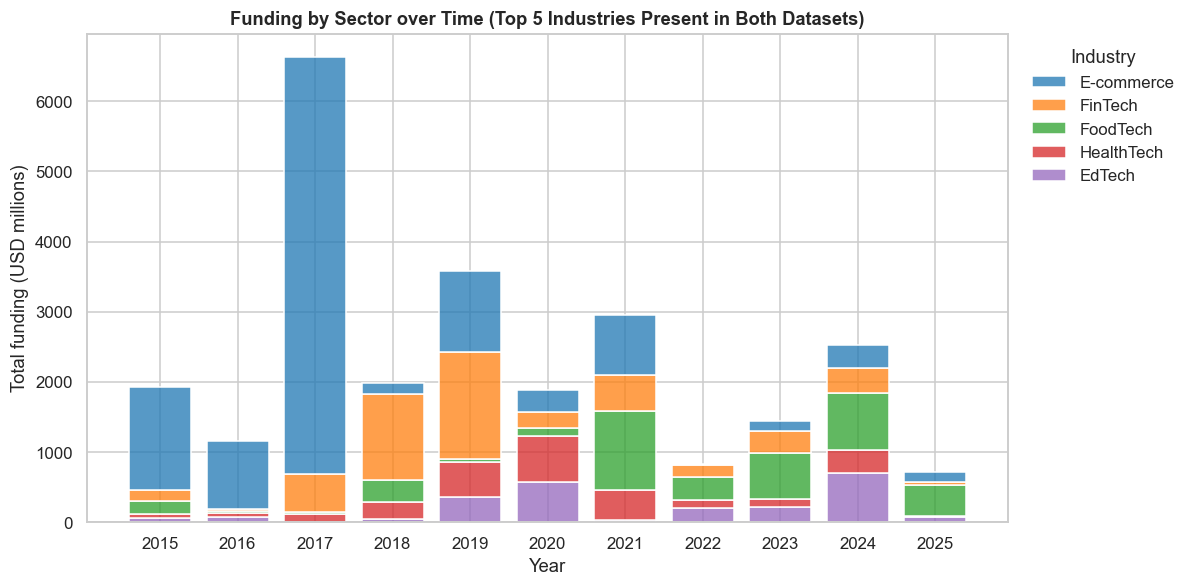

In [32]:
# Keep only industries with at least 15 deals in BOTH datasets
ct = pd.crosstab(df["Industry_Clean"], df["Data Source"])
common = ct[(ct >= 15).all(axis=1)].index.difference(UNKNOWN)

ind = funded[funded["Industry_Clean"].isin(common)]
top5 = ind.groupby("Industry_Clean")["Amount_M"].sum().nlargest(5).index.tolist()
d2 = ind[ind["Industry_Clean"].isin(top5)]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.histplot(data=d2, x="Year", weights="Amount_M", hue="Industry_Clean",
             hue_order=top5, multiple="stack", discrete=True, shrink=0.8,
             palette="tab10", edgecolor="white", ax=ax)
ax.set_xticks(sorted(d2["Year"].unique()))
ax.set_xlabel("Year")
ax.set_ylabel("Total funding (USD millions)")
ax.set_title("Funding by Sector over Time (Top 5 Industries Present in Both Datasets)")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1), title="Industry", frameon=False)
plt.tight_layout()
plt.show()

In [33]:
pv = d2.pivot_table(index="Year", columns="Industry_Clean", values="Amount_M",
                    aggfunc="sum", fill_value=0)[top5]
display((pv.div(pv.sum(axis=1), axis=0) * 100).round(1))

Industry_Clean,E-commerce,FinTech,FoodTech,HealthTech,EdTech
Year,,,,,
2015,76.2,8.4,9.1,3.2,3.1
2016,83.7,2.7,2.0,4.5,7.1
2017,89.6,8.3,0.3,1.8,0.1
2018,7.8,62.0,15.9,12.1,2.3
2019,32.3,42.7,1.0,14.1,10.1
2020,16.4,12.6,5.7,34.7,30.6
2021,28.6,17.7,38.2,14.3,1.2
2022,1.7,20.5,40.1,12.4,25.2
2023,10.0,21.3,45.7,8.0,15.0


### Insight 2 – Sector shift

- **E-commerce is the largest funded sector overall**, followed by FinTech, FoodTech, HealthTech and EdTech. These five are the top sectors among industries present in both datasets, and together they take **86%** of the disclosed funding in that comparable group, so funding within it is highly concentrated.
- **The leading sector changes over time.** E-commerce tops the chart each year from 2015 to 2017, FinTech leads in 2018 and 2019, HealthTech in 2020, and **FoodTech every year from 2021 to 2025**.
- **E-commerce lost the most share (-72.3 pp, from 81.2% to 8.9%)** between 2015–2017 and 2023–2025. **FoodTech gained the most (+25.3 pp, from 2.1% to 27.5%)**, followed by **EdTech (+13.0 pp)**, **HealthTech (+4.2 pp)** and **FinTech (+2.9 pp)**.
- This **partly supports** the expectation that funding moved away from e-commerce towards newer sectors. E-commerce clearly declined, and FinTech and HealthTech did gain share, but only modestly. The biggest gains went to **FoodTech and EdTech**, which were not in the expected list, and SaaS does not appear in the top 5. Consumer Internet cannot be assessed at all, because it appears only in the 2015–2020 dataset.
- **Caution:** the early period (2015–2017) comes only from the first dataset and the recent period (2023–2025) only from the second, so every share shift compares two different sources. The second dataset is a sample, and one sector leading every year from 2021 to 2025 is unusually stable for a real market. The size of the shifts (for example, 81% to 9% for e-commerce) may therefore be exaggerated by how the data was collected, and the direction of change is more reliable than the exact percentages.

## 13. Visualization 3 – City-wise Total Funding (Seaborn)

**Chart type:** horizontal bar chart of the top 10 cities.
**Purpose:** show spatial variation – which cities are the main funding hubs and how concentrated funding is.
**Design choices:**
- Only 8 cities have meaningful funding (the other two in the top 10 are below 0.5%), so showing more bars would add noise.
- City names are standardized (e.g. *Bangalore → Bengaluru*; Gurugram, Noida and New Delhi are grouped as *Delhi NCR*).
- Horizontal bars keep long city names readable, and values are printed at the bar ends so exact numbers can be read.

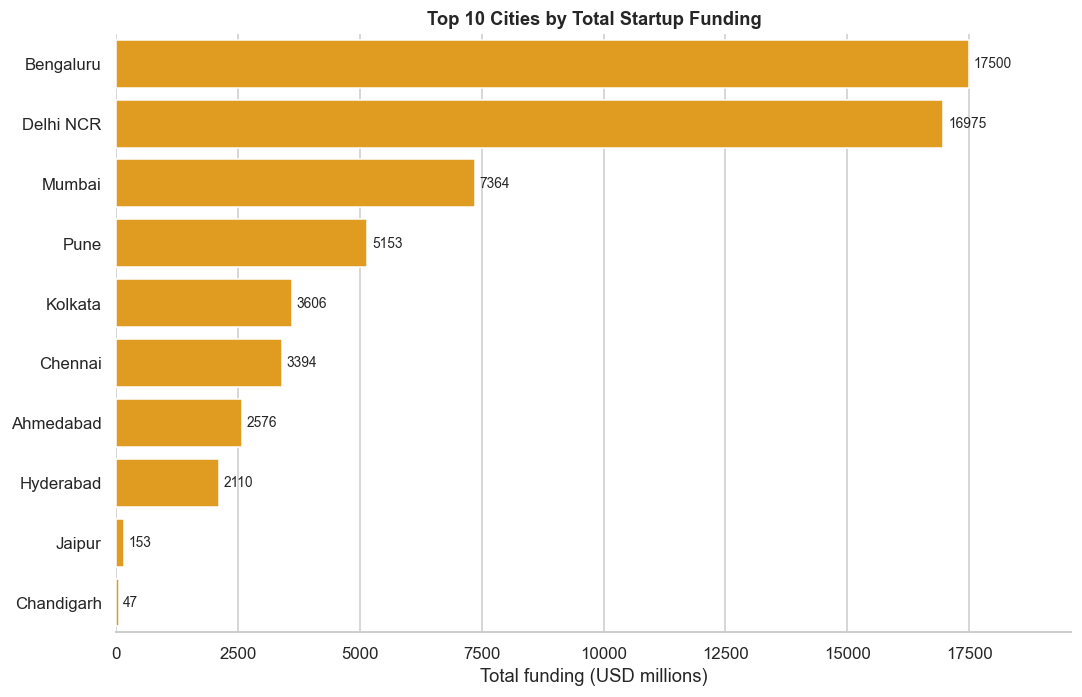

In [34]:
cities = funded[~funded["City_Clean"].isin(UNKNOWN)]
city_tot = (cities.groupby("City_Clean")["Amount_M"].sum()
                  .nlargest(10).rename("Funding_M").reset_index())

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.barplot(data=city_tot, x="Funding_M", y="City_Clean", color="orange", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3, fontsize=9)
ax.set_xlabel("Total funding (USD millions)")
ax.set_ylabel("")
ax.set_title("Top 10 Cities by Total Startup Funding")
ax.set_xlim(0, city_tot["Funding_M"].max() * 1.12)
sns.despine(left=True)
plt.tight_layout()
plt.show()

In [35]:
city_tot["Share_%"] = city_tot["Funding_M"] / cities["Amount_M"].sum() * 100
display(city_tot.round(1))

tier2 = ["Jaipur", "Ahmedabad", "Kochi", "Indore", "Chandigarh", "Coimbatore", "Lucknow",
         "Surat", "Nagpur", "Bhopal", "Visakhapatnam", "Vadodara", "Thiruvananthapuram",
         "Mysore", "Mysuru", "Bhubaneswar", "Patna", "Ludhiana", "Kanpur", "Nashik"]
known = df[~df["City_Clean"].isin(UNKNOWN)]
t2 = (known.assign(Tier2=known["City_Clean"].isin(tier2))
           .groupby("Year")["Tier2"].mean().mul(100).round(1)
           .rename("Tier-2 share of deals (%)"))
display(t2.to_frame())

,City_Clean,Funding_M,Share_%
0,Bengaluru,17499.7,29.6
1,Delhi NCR,16974.8,28.7
2,Mumbai,7364.0,12.5
3,Pune,5153.1,8.7
4,Kolkata,3606.5,6.1
5,Chennai,3393.8,5.7
6,Ahmedabad,2576.0,4.4
7,Hyderabad,2109.7,3.6
8,Jaipur,152.7,0.3
9,Chandigarh,47.1,0.1


,Tier-2 share of deals (%)
Year,
2015,3.8
2016,5.9
2017,3.1
2018,4.3
2019,2.0
2020,11.4
2021,6.0
2022,8.5
2023,11.7


### Insight 3 – Geographic concentration

- **Funding is highly concentrated in three cities.** Bengaluru leads narrowly with **29.6%** of disclosed funding, followed by Delhi NCR (**28.7%**) and Mumbai (**12.5%**). Together they hold **70.8%**, which matches the expectation that Bengaluru, Delhi NCR and Mumbai remain the main hubs.
- **The long tail is very thin.** Pune (8.7%), Kolkata (6.1%), Chennai (5.7%), Ahmedabad (4.4%) and Hyderabad (3.6%) complete the top 8, which holds about **99.3%** of funding. The only other cities in the top 10, Jaipur (0.3%) and Chandigarh (0.1%), are negligible.
- **Tier-2 activity looks higher after 2020, but the evidence is weak.** Tier-2 cities were **2.0–5.9%** of deals in 2015–2019, then **11.4% in 2020** and **11.7–12.0% in 2023–2024**. This is consistent with growing activity outside the big metros, but it coincides with the switch to the second dataset.
- **Caution:** the second dataset spreads deals almost evenly across eight cities (96–116 each, except Delhi NCR with 341). Kolkata has 21 deals in the first dataset but 116 in the second, and Ahmedabad has 38 against 111, so the ranking of mid-sized cities is partly an artifact of the data source, and Ahmedabad drives the tier-2 jump. The positions of Bengaluru, Delhi NCR and Mumbai are more reliable, since they also lead in the first dataset alone (850, 893 and 572 deals). City is missing for 180 deals, and amounts are missing for others, so city totals are lower bounds.

## 14. Visualization 4 – Funding Amount by Investment Stage (Seaborn)

**Chart type:** boxplot on a logarithmic y-axis.
**Purpose:** compare the typical deal size and spread across funding stages Angel → Seed → Series A/B/C → Growth, with Private Equity and Debt shown for comparison and identify outliers.
**Design choices:** 
- *Private Equity* and *Debt* are investor and instrument types rather than lifecycle stages, so they are shown after the lifecycle stages (Angel → Growth) for comparison, not as later stages.
- Deal sizes span several orders of magnitude, so a **log scale** is used; on a linear axis the large deals would flatten every other box.
- Only stages with at least 15 disclosed deals are shown, ordered from early to late stage.

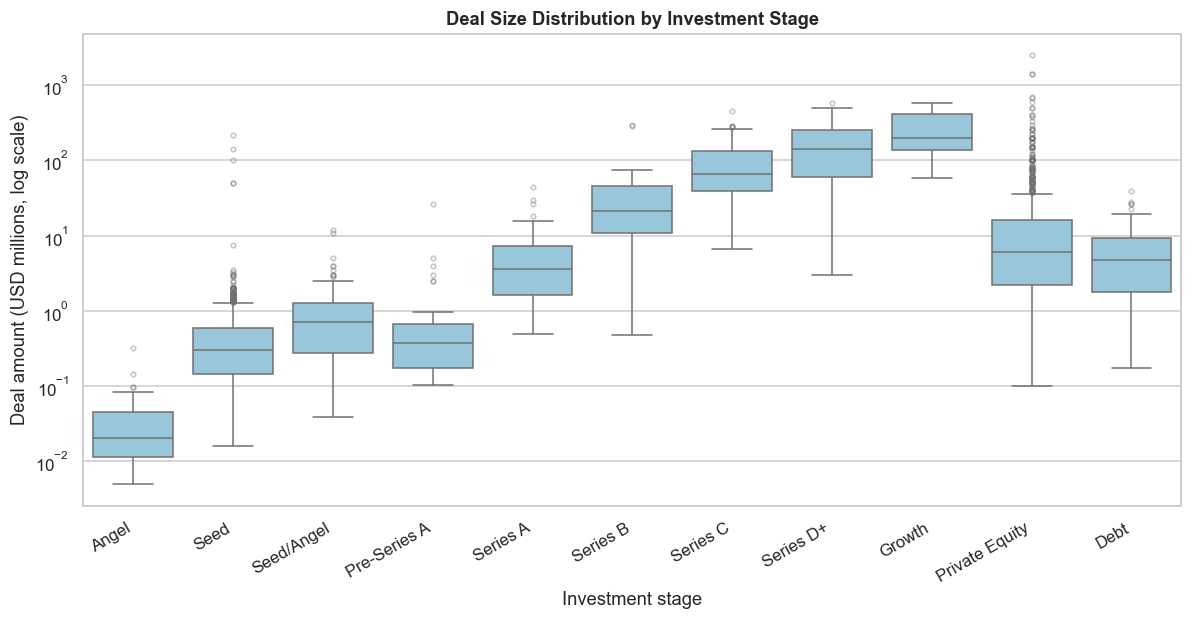

In [36]:
stage_order = ["Angel", "Seed", "Seed/Angel", "Pre-Series A", "Series A", "Series B",
               "Series C", "Series D+", "Venture", "Growth", "Private Equity", "Debt"]
stg = funded[~funded["Stage"].isin(UNKNOWN)]
counts = stg["Stage"].value_counts()
keep = [s for s in stage_order if counts.get(s, 0) >= 15]
d4 = stg[stg["Stage"].isin(keep)]

fig, ax = plt.subplots(figsize=(11, 5.8))
sns.boxplot(data=d4, x="Stage", y="Amount_M", order=keep, color="#8ecae6",
            flierprops=dict(marker="o", markersize=3, alpha=0.4), ax=ax)
ax.set_yscale("log")
ax.set_xlabel("Investment stage")
ax.set_ylabel("Deal amount (USD millions, log scale)")
ax.set_title("Deal Size Distribution by Investment Stage")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [37]:
stats = (d4.groupby("Stage")["Amount_M"]
           .agg(Deals="count", Median="median", Q1=lambda s: s.quantile(.25),
                Q3=lambda s: s.quantile(.75), Max="max")
           .reindex(keep))
display(stats.round(2))

,Deals,Median,Q1,Q3,Max
Stage,,,,,
Angel,64,0.02,0.01,0.05,0.32
Seed,1156,0.30,0.15,0.60,220.00
Seed/Angel,108,0.71,0.27,1.26,12.00
Pre-Series A,96,0.38,0.17,0.66,26.00
Series A,249,3.56,1.62,7.38,45.00
Series B,131,21.32,10.80,45.53,300.00
Series C,109,65.87,38.93,132.06,450.00
Series D+,42,140.39,59.47,251.19,585.00
Growth,25,197.38,138.15,419.74,574.68


### Insight 4 – Deal size by stage

- **Deal size rises sharply across the lifecycle stages.** Median deal size grows from **USD 0.02M at Angel** and **USD 0.30M at Seed** to **USD 3.56M at Series A**, **USD 21.3M at Series B**, **USD 65.9M at Series C**, **USD 140.4M at Series D+** and **USD 197.4M at Growth**. Growth deals are about four orders of magnitude larger than Angel deals at the median, which fits the normal funding lifecycle.
- **The step-up shrinks in later stages.** The median is about 12 times larger at Series A than at Seed, about 6 times larger at Series B than at Series A, about 3 times at Series C, about 2 times at Series D+, and only about 1.4 times at Growth.
- **Private Equity does not follow the lifecycle pattern.** It is the second-largest group (1,076 deals) but has a median of only **USD 6.0M**, far below Series C, Series D+ and Growth, which suggests the label covers deals of very different sizes. It also has the widest relative spread of any group (Q3 is about 7 times Q1, with the middle 50% of deals between USD 2.2M and USD 16M) and contains the largest deal in the dataset, **Flipkart's USD 2,500M round in 2017**, roughly 400 times the Private Equity median. **Debt** deals are smaller and more uniform (48 deals, median USD 4.75M, maximum USD 39.6M).
- **Spread varies elsewhere too.** Growth has the widest absolute spread among the lifecycle stages (the middle 50% of deals lie between USD 138M and USD 420M). Angel deals are consistently very small (middle 50% between USD 0.01M and USD 0.05M).
- **Outliers pull averages up.** The largest Seed deal (USD 220M) is hundreds of times the Seed median (USD 0.30M), and the largest Series B deal (USD 300M) is about 14 times its median. The **median** is therefore a better summary than the mean for deal size.
- **Seed and Private Equity dominate deal counts.** Together they account for 2,232 of the 3,104 deals shown (about 72%), but Seed deals are small, so Seed contributes little to total funding.
- **Caution:** Series D+ (42 deals), Growth (25 deals) and Debt (48 deals) are small groups, so their boxes are less reliable. *Private Equity* and *Debt* are investor and instrument types, not lifecycle stages, so they should not be read as "later" than Growth. The mixed Seed/Angel category has a higher median (USD 0.71M) than Seed or Pre-Series A because it combines two labels. Amounts are missing for part of the data, so the box plots show disclosed deals only.


## 15. Visualization 5 – Industry × Year Funding Intensity (Seaborn)

**Chart type:** heatmap (industries on the rows, years on the columns, total funding in each cell).
**Purpose:** show which sectors attracted the most investor attention in which years, and how that attention moved across the decade.
**Design choices:**
- Only the **7 industries present in both datasets** are shown (at least 15 deals in each dataset), because the two sources use different industry labels.
- Funding differs by several orders of magnitude between cells, so colour is on a **logarithmic scale**; on a linear scale a few huge cells would hide everything else.
- Each cell is labelled with its value (USD millions). **Blank cells mean no disclosed funding**, not zero.

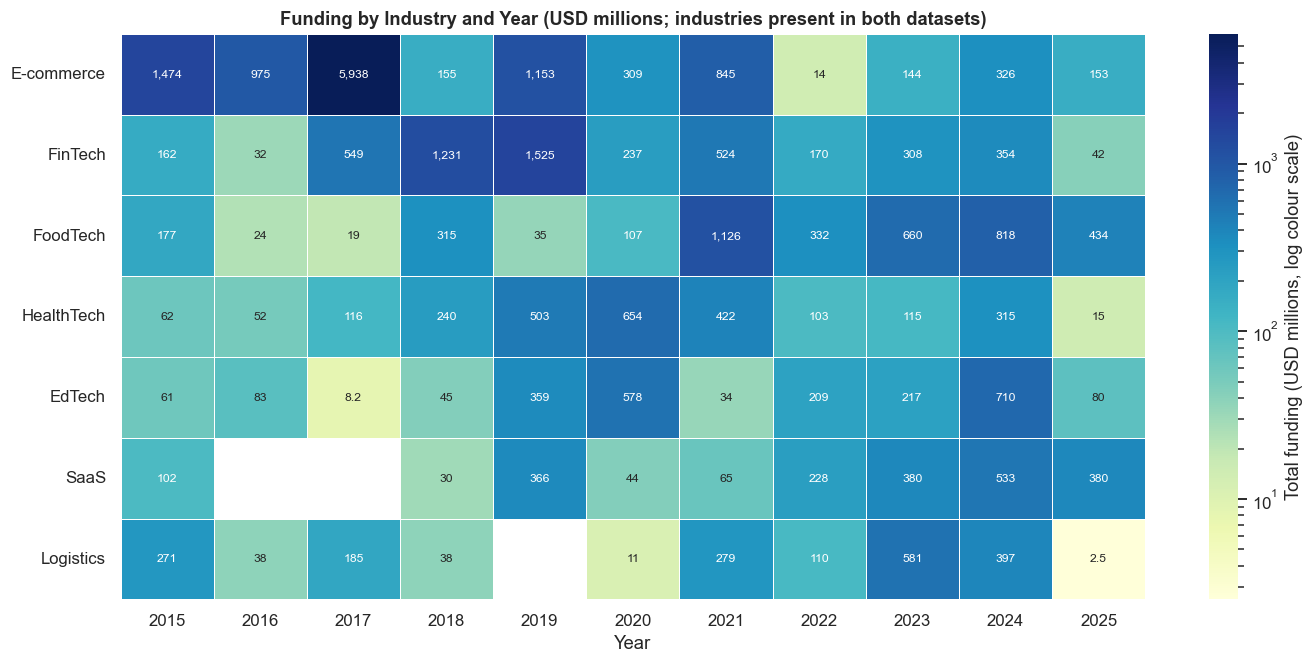

In [38]:
# Industries present in both datasets (same rule as Visualization 2)
ct = pd.crosstab(df["Industry_Clean"], df["Data Source"])
common = ct[(ct >= 15).all(axis=1)].index.difference(UNKNOWN)

ind5 = funded[funded["Industry_Clean"].isin(common)]
top_ind = ind5.groupby("Industry_Clean")["Amount_M"].sum().nlargest(10).index

heat = (ind5[ind5["Industry_Clean"].isin(top_ind)]
        .pivot_table(index="Industry_Clean", columns="Year", values="Amount_M", aggfunc="sum")
        .reindex(top_ind))                       # rows sorted by total funding

# Cell labels: one decimal for small values, whole numbers for large ones
labels = heat.apply(lambda col: col.map(
    lambda v: "" if pd.isna(v) else (f"{v:,.1f}" if v < 10 else f"{v:,.0f}")))

fig, ax = plt.subplots(figsize=(13, 6.2))
sns.heatmap(heat, cmap="YlGnBu", norm=LogNorm(vmin=np.nanmin(heat.values), vmax=np.nanmax(heat.values)),
            annot=labels, fmt="", annot_kws={"size": 8}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Total funding (USD millions, log colour scale)"}, ax=ax)
ax.set_xlabel("Year")
ax.set_ylabel("")
ax.set_title("Funding by Industry and Year (USD millions; industries present in both datasets)")
plt.tight_layout()
ax.grid(False)
plt.show()

In [39]:
peak = pd.DataFrame({
    "Peak year": heat.idxmax(axis=1),
    "Peak funding (USD M)": heat.max(axis=1).round(0),
    "Total funding (USD M)": heat.sum(axis=1).round(0),
    "Years with funding": heat.notna().sum(axis=1),
})
display(peak)

,Peak year,Peak funding (USD M),Total funding (USD M),Years with funding
Industry_Clean,,,,
E-commerce,2017,5938.0,11486.0,11
FinTech,2019,1525.0,5133.0,11
FoodTech,2021,1126.0,4047.0,11
HealthTech,2020,654.0,2597.0,11
EdTech,2024,710.0,2383.0,11
SaaS,2024,533.0,2127.0,9
Logistics,2023,581.0,1913.0,10


### Insight 5 – Industry × Year funding intensity

- **E-commerce is the hottest cell on the heatmap by a wide margin.** Its 2017 funding of **USD 5,938M** is nearly four times the next-largest industry peak (FinTech in 2019, USD 1,525M). E-commerce also has the largest total (**USD 11,486M**), about 39% of the funding across the seven industries and more than twice FinTech's USD 5,133M. Together, E-commerce and FinTech hold about 56% of the total.
- **E-commerce funding came in one boom, while the other sectors were steadier.** E-commerce's peak year holds about **52%** of its total funding. For the other six industries the peak year holds only about **25–30%** of their total, which means their funding was spread more evenly across the years.
- **The peak year moves from older sectors to newer ones.** E-commerce peaks in 2017, FinTech in 2019, HealthTech in 2020, FoodTech in 2021, Logistics in 2023, and EdTech and SaaS in 2024. This partly supports the expectation that investor attention shifted from e-commerce towards FinTech, HealthTech and SaaS, but the newer sectors' peaks (USD 533M to USD 1,525M) are far smaller than e-commerce's 2017 peak.
- **Most sectors received funding in every year.** E-commerce, FinTech, FoodTech, HealthTech and EdTech have disclosed funding in all 11 years, Logistics in 10 and SaaS in 9. The blank cells for those two sectors mean no disclosed funding in those years, not zero funding.
- **Caution:** five of the seven peak years (2020 to 2024) fall in the second dataset, which is a sample that spreads moderate-sized deals across all sectors. The "newer sectors peak later" pattern may therefore partly reflect the data source, as with the sector shifts in Insight 2. E-commerce's 2017 peak is driven by three deals (two Flipkart rounds of USD 2,500M and USD 1,400M and one Paytm round of USD 1,400M), which together make up about 89% of that cell.

## 16. Visualization 6 – Deal Amount vs Date, by Sector (Plotly)

**Chart type:** interactive scatter / bubble chart (each bubble is one deal; bubble size and height show the amount).
**Purpose:** explore the relationship between **when** a deal happened, **how large** it was and **which sector** it belongs to, with company-level detail on hover.
**Design choices:**
- The y-axis is **logarithmic**, because deal sizes range from a few thousand dollars to over USD 2 billion.
- Only the **8 sectors with the most funded deals** get their own colour; all others are grouped as *Other sectors*.
- A dashed line marks 2020, where the two datasets overlap, so changes in the pattern around that year can be read with the source switch in mind.
- Hover over a bubble to see the startup name, stage, city and exact amount. Click a legend entry to hide or show a sector.

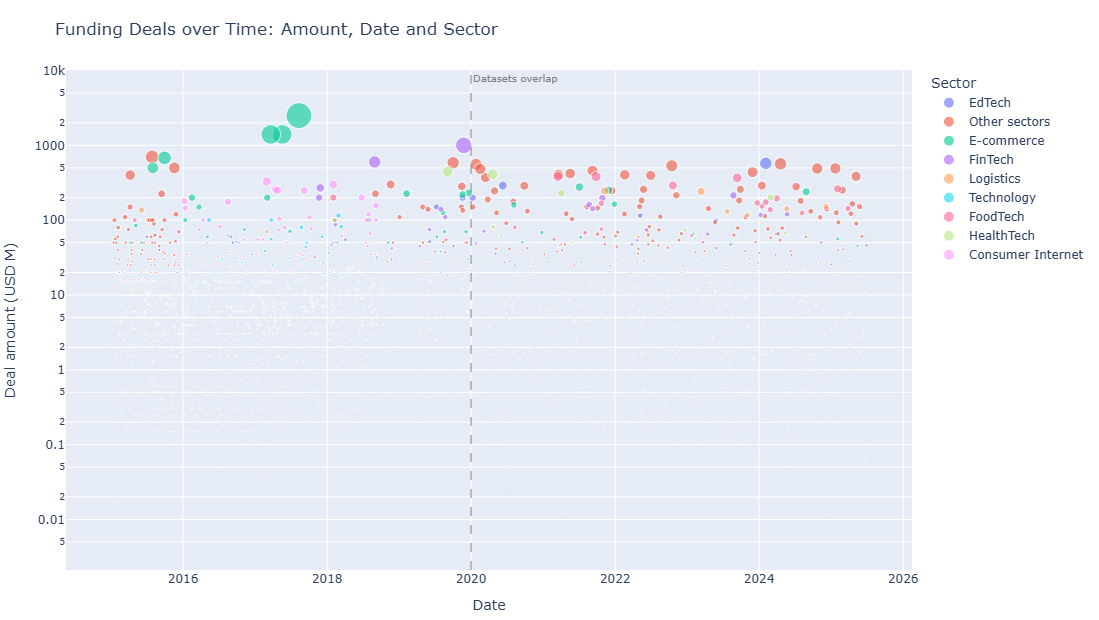

In [40]:
sector_counts = funded["Industry_Clean"].value_counts()
top_sectors = [s for s in sector_counts.index if s not in UNKNOWN][:8]
d6 = funded.assign(Sector=np.where(funded["Industry_Clean"].isin(top_sectors),
                                   funded["Industry_Clean"], "Other sectors"))

fig = px.scatter(
    d6, x="Date", y="Amount_M", color="Sector", size="Amount_M", size_max=26,
    opacity=0.6, log_y=True, hover_name="Startup",
    hover_data={"Stage": True, "City_Clean": True, "Amount_M": ":,.2f",
                "Date": "|%d %b %Y", "Sector": False},
    labels={"Amount_M": "Deal amount (USD M)", "City_Clean": "City"},
    title="Funding Deals over Time: Amount, Date and Sector",
    height=620,
)
fig.add_shape(type="line", x0="2020-01-01", x1="2020-01-01", y0=0, y1=1, yref="paper",
              line=dict(dash="dash", color="gray", width=1))
fig.add_annotation(x="2020-01-01", y=1, yref="paper", text="Datasets overlap", showarrow=False,
                   xanchor="left", yanchor="top", font=dict(size=10, color="gray"))
fig.update_layout(legend_title_text="Sector", margin=dict(t=70, r=10, l=10, b=10))
fig.show()

In [41]:
by_year = (funded.assign(Mega=funded["Amount_M"] >= 100)
                 .groupby("Year")
                 .agg(Funded_deals=("Amount_M", "size"),
                      Median_deal_USD_M=("Amount_M", "median"),
                      Deals_100M_plus=("Mega", "sum")))
display(by_year.round(2))

display(funded.nlargest(10, "Amount_M")[["Startup", "Industry_Clean", "Stage", "City_Clean", "Year", "Amount_M"]].round(1))

,Funded_deals,Median_deal_USD_M,Deals_100M_plus
Year,,,
2015,647,1.50,17
2016,586,1.00,8
2017,456,2.25,13
2018,265,4.00,15
2019,104,12.00,17
2020,202,1.13,14
2021,183,1.04,19
2022,200,1.15,11
2023,213,1.03,11


,Startup,Industry_Clean,Stage,City_Clean,Year,Amount_M
651,Flipkart,E-commerce,Private Equity,Bengaluru,2017,2500.0
830,Paytm,E-commerce,Private Equity,Bengaluru,2017,1400.0
966,Flipkart,E-commerce,Private Equity,Bengaluru,2017,1400.0
31,Paytm,FinTech,Funding Round,Delhi NCR,2019,1000.0
2648,Flipkart.com,Online Marketplace,Private Equity,Bengaluru,2015,700.0
2459,Paytm,E-commerce,Private Equity,Delhi NCR,2015,680.0
188,True North,FinTech,Private Equity,Mumbai,2018,600.0
33,Udaan,B2B,Series D+,Bengaluru,2019,585.0
4059,CoreSpace,EdTech,Growth,Bengaluru,2024,574.7
3869,BharatPe,Consumer Electronics,Growth,Pune,2024,566.6


### Insight 6 – Deal amount, timing and sector

- **The typical deal is small, and very large deals are rare but persistent.** The median disclosed deal is only about **USD 1.0–1.6M** in most years (2015, 2016 and 2020–2025). Deals of USD 100M or more are only about **5%** of funded deals (155 of 3,165), yet there are 8 to 21 of them every year, so large rounds appear throughout the decade instead of in one boom.
- **Between 2015 and 2019 the market shifted towards larger disclosed deals.** Funded deals fell from 647 to 104 (-84%), while the number of USD 100M+ deals stayed in the range of 8 to 17 per year. Large deals therefore grew from **2.6% of funded deals in 2015 to 16.3% in 2019**, and the median rose from USD 1.0M (2016) to USD 4.0M (2018) and **USD 12.0M (2019)**. Smaller deals may simply have been disclosed less often in later years, so this may reflect reporting as much as investor behaviour.
- **The median drops about tenfold in 2020, which matches the dataset switch.** It falls from USD 12.0M in 2019 to **USD 1.13M in 2020** and stays near USD 1.0–1.6M through 2025. Funded deals also rise from 104 to 202. This pattern fits the second dataset containing many small deals, so it should be read as a feature of the data, not as a market collapse.
- **The ten largest deals are dominated by two companies.** Flipkart and Paytm account for **6 of the top 10** (USD 7,680M in total), led by Flipkart's **USD 2,500M** round in 2017. Eight of the ten largest deals fall in 2015–2019, five of them in 2015–2017, so the biggest rounds come from the first dataset.
- **Large deals after 2020 are less reliable.** The two largest deals of 2024 (CoreSpace, USD 574.7M, and BharatPe, USD 566.6M) come from the sample dataset, where company names, sectors and cities do not match the real companies (BharatPe is tagged *Consumer Electronics* in Pune, which does not match the real company). The 2024 count of 21 deals above USD 100M, the highest of any year, should be treated with caution.
- **Caution:** the same company is classified differently across rows (Flipkart appears as *E-commerce* and *Online Marketplace*; Paytm as *E-commerce* and *FinTech*), so a single company can appear under two sector colours in the scatter. The Rapido currency error was corrected before these figures were produced.

## 17. Visualization 7 – Investment-Type Share of Total Deals (Plotly)

**Chart type:** treemap (rectangle area is proportional to the number of deals).
**Purpose:** show the overall composition of funding rounds across the whole 2015–2025 period.
**Design choices:**
- The treemap counts **all deals, including those with an undisclosed amount**, because the question is about deal composition and not about money.
- Only the **9 most common investment types** are named; the rest are grouped as *Other types*.
- The share of deals is printed in each rectangle.

In [42]:
d7 = df[~df["Stage"].isin(UNKNOWN)]
top_types = d7["Stage"].value_counts().nlargest(9).index
d7 = d7.assign(Type=np.where(d7["Stage"].isin(top_types), d7["Stage"], "Other types"))

tm = d7.groupby("Type").size().rename("Deals").reset_index().sort_values("Deals", ascending=False)
tm["Share_%"] = (tm["Deals"] / tm["Deals"].sum() * 100).round(1)
tm["Label"] = (tm["Type"] + "<br>" + tm["Deals"].map("{:,}".format) + " deals ("
               + tm["Share_%"].map("{:.1f}%".format) + ")")

fig = px.treemap(tm, path=["Label"], values="Deals", color="Deals",
                 color_continuous_scale="Blues", title="Share of Deals by Investment Type (2015–2025)",
                 height=560)
fig.update_traces(textfont_size=15, textposition="middle center")
fig.update_layout(coloraxis_showscale=False, margin=dict(t=70, l=10, r=10, b=10))
fig.show()

In [43]:
display(tm[["Type", "Deals", "Share_%"]].reset_index(drop=True))

# Does the mix depend on the data source? (share of each dataset's deals, %)
display(pd.crosstab(d7["Type"], d7["Data Source"], normalize="columns").mul(100).round(1)
          .reindex(tm["Type"]))

,Type,Deals,Share_%
0,Seed,1805,43.6
1,Private Equity,1366,33.0
2,Series A,251,6.1
3,Seed/Angel,138,3.3
4,Series B,131,3.2
5,Other types,128,3.1
6,Series C,109,2.6
7,Pre-Series A,97,2.3
8,Angel,65,1.6
9,Debt,50,1.2


Data Source,2015-2020 Dataset,2020-2025 Dataset
Type,,
Seed,46.1,36.7
Private Equity,44.8,0.5
Series A,0.8,20.6
Seed/Angel,4.5,0.0
Series B,0.7,10.0
Other types,1.3,8.0
Series C,0.5,8.6
Pre-Series A,0.3,8.0
Angel,0.1,5.6


### Insight 7 – Investment-type share of deals

- **Seed deals make up the largest share.** Seed accounts for **1,805 of the 4,140 deals** with a known type (**43.6%**), and Seed plus Private Equity (**33.0%**) together make up **76.6%** of all deals. Adding the smaller early-stage labels (Seed/Angel 3.3%, Pre-Series A 2.3%, Angel 1.6%), about **half of all deals (50.8%)** are early-stage rounds.
- **Deal counts fall sharply at later stages.** Series A has 251 deals (6.1%), Series B 131 (3.2%) and Series C 109 (2.6%), so each later stage has far fewer deals than Seed. These are counts of different companies and periods, not conversion rates, but they match the usual funnel in which few startups reach later rounds. Debt is the smallest named type at **1.2%** (50 deals).
- **The mix is driven by the data source.** **Private Equity is 44.8% of the 2015–2020 deals but only 0.5% of the 2020–2025 deals**, so almost all Private Equity deals come from the first dataset. The reverse holds for later rounds: Series A, B, C, Pre-Series A and Angel together make up **52.8%** of the second dataset but only **2.4%** of the first. *Seed/Angel* exists only in the first dataset (4.5%) and not at all in the second.
- **The two sources describe different markets.** The first dataset is dominated by two labels (Seed 46.1% and Private Equity 44.8%, together 91%). The second dataset spreads deals across many stages (Seed 36.7%, Series A 20.6%, Series B 10.0%, Series C 8.6%, Pre-Series A 8.0%, other types 8.0%, Angel 5.6%), which is typical of a generated sample.
- **Caution:** the treemap shows the **combined** dataset, so its shares are a blend of the two sources, not the composition of the real market. The sources also label rounds differently (for example *Private Equity Round* and *Seed Round* versus *Series A*), so a type's share can change simply because of how it was labelled. Four deals with no investment type are excluded, so the shares are based on 4,140 deals.

## 18. Visualization 8 – Top 10 Most Active Investors (Seaborn)

**Chart type:** horizontal bar chart.
**Purpose:** identify which investors take part in the largest number of deals (investor participation).
**Design choices:**
- A deal with several investors counts once for **each** investor, so the bars show **deals participated in**, not deals led.
- Entries such as *Undisclosed Investors* or *Not specified* are removed, and common spelling variants of the same investor are merged.
- The measure is a **deal count**, not a funding amount, so it includes deals with an undisclosed amount.

In [44]:
# ---- Split multi-investor rows into one row per (deal, investor) ----
inv = df[["Investors", "Data Source"]].copy()
inv["Deal"] = inv.index
inv["Investor"] = strip_junk(inv["Investors"]).str.split(r"[,;]", regex=True)
inv = inv.explode("Investor")
inv["Investor"] = inv["Investor"].str.strip()
inv["key"] = inv["Investor"].str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.strip()

# ---- Remove non-names ----
skip = {"", "nan", "na", "not specified", "undisclosed", "undisclosed investors",
        "undisclosed investor", "others", "other", "angel investors", "angel investor",
        "private investors", "existing investors", "individual investors"}
inv = inv[~inv["key"].isin(skip)]

# ---- Merge obvious spelling variants (extend after checking the list below) ----
canon = {
    "sequoia capital": "Sequoia Capital India", "sequoia india": "Sequoia Capital India",
    "sequoia capital india": "Sequoia Capital India",
    "accel partners": "Accel", "accel india": "Accel", "accel": "Accel",
    "tiger global": "Tiger Global Management", "tiger global management": "Tiger Global Management",
    "nexus venture partners": "Nexus Venture Partners", "nexus venture": "Nexus Venture Partners",
}
inv["Investor"] = inv["key"].map(canon).fillna(inv["Investor"])
inv = inv.drop_duplicates(["Deal", "Investor"])

# Check this list for duplicate spellings, then add them to `canon` above if needed
display(inv["Investor"].value_counts().head(25))


Investor
Sequoia Capital India        188
Tiger Global Management      185
Accel                        155
Kalaari Capital              127
Blume Ventures               114
Nexus Venture Partners       104
Y Combinator                  92
Omidyar Network               87
Info Edge                     85
Mirae Asset                   83
IFC                           80
Zodius Capital                79
Bessemer Venture Partners     78
Ribbit Capital                75
Prosus Ventures               75
Matrix Partners India         71
SoftBank Vision Fund          70
Kedaara Capital               70
Peak XV                       69
Falcon Edge                   67
Elevation Capital             67
A91 Partners                  65
Ventures India                65
LCatterton                    64
Lightspeed India              58
Name: count, dtype: int64

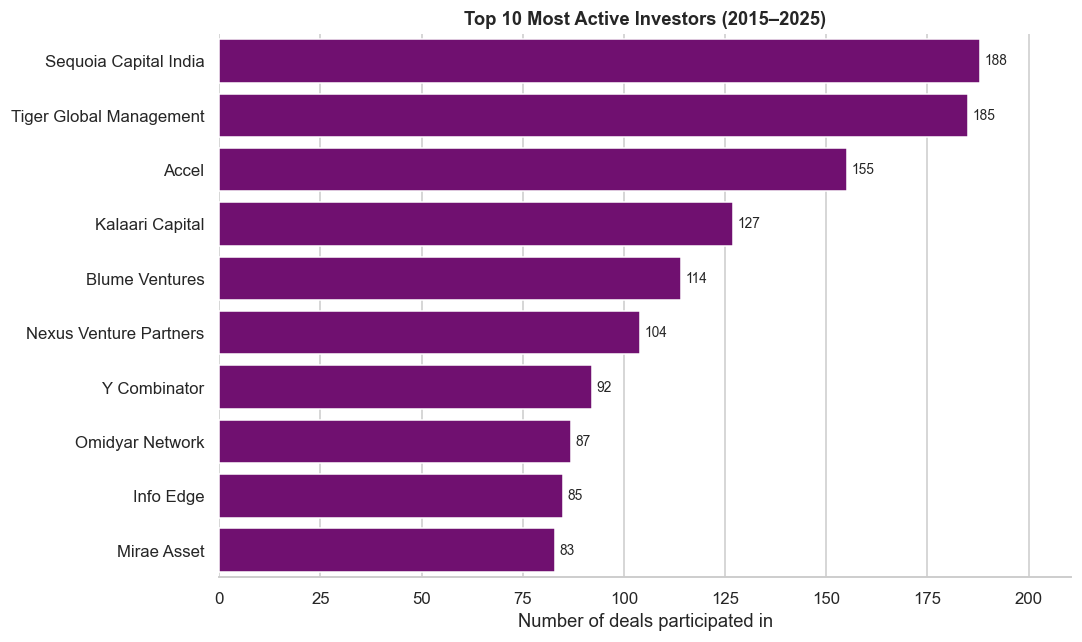

In [45]:
top_inv = inv["Investor"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_inv.values, y=top_inv.index, color="purple", ax=ax)
ax.bar_label(ax.containers[0], fmt="%d", padding=3, fontsize=9)
ax.set_xlabel("Number of deals participated in")
ax.set_ylabel("")
ax.set_title("Top 10 Most Active Investors (2015–2025)")
ax.set_xlim(0, top_inv.max() * 1.12)
sns.despine(left=True)
plt.tight_layout()
plt.show()

In [46]:
tbl = (inv[inv["Investor"].isin(top_inv.index)]
         .groupby(["Investor", "Data Source"]).size().unstack(fill_value=0)
         .reindex(top_inv.index))
tbl["Total"] = tbl.sum(axis=1)
display(tbl)

Data Source,2015-2020 Dataset,2020-2025 Dataset,Total
Investor,,,
Sequoia Capital India,111,77,188
Tiger Global Management,49,136,185
Accel,75,80,155
Kalaari Capital,50,77,127
Blume Ventures,47,67,114
Nexus Venture Partners,31,73,104
Y Combinator,8,84,92
Omidyar Network,20,67,87
Info Edge,3,82,85


### Insight 8 – Most active investors

- **Sequoia Capital India and Tiger Global Management lead, almost level.** Sequoia Capital India took part in **188 deals** and Tiger Global Management in **185**, a gap of only 3 deals. Accel follows with **155**, then Kalaari Capital (127) and Blume Ventures (114). There is a visible gap between the top three and the rest (155 to 127 between third and fourth place), so a small group of firms participates in the most deals.
- **Participation is spread widely across firms.** The tenth-ranked investor, Mirae Asset, still took part in 83 deals, so the top 10 investors together account for **1,220 deal participations**. This is a measure of how often an investor takes part, not how much it invests, because the chart counts deals with an undisclosed amount too.
- **The ranking depends heavily on the second dataset.** **826 of the 1,220 participations (68%)** come from the 2020–2025 dataset, although that dataset contains only about 27% of all deals (1,100 of 4,144). In that dataset, nine of the ten investors have between 67 and 84 deals each, a very even spread, which is typical of a generated sample drawn from a fixed list of investors.
- **Some investors appear active mainly because of the sample data.** Mirae Asset has **0 deals** in the 2015–2020 dataset and **83** in the 2020–2025 one. Info Edge has 3 versus 82 and Y Combinator 8 versus 84. Tiger Global has 49 versus 136, so about 74% of its count comes from the second dataset. By contrast, Sequoia Capital India (111) and Accel (75) are the only two investors with substantial activity in the first dataset as well.
- **Caution:** each deal counts once for every investor listed, so a deal with three investors adds to three bars. Similar names were merged only for the few variants listed in the cleaning code, so an investor can still be split across spellings. *Peak XV*, the 2023 rebrand of Sequoia Capital India, is counted separately unless it was merged, which means Sequoia's total may be understated. Treat the order of the top 10 as indicative, and treat the first dataset's counts as the more reliable picture of real investor behaviour.

## 19. Visualization 9 – Intentionally Misleading Chart (Matplotlib)

**Purpose:** to show how easily a correct dataset can be made to tell a false story. The chart below uses the **real funding totals for 2021–2024** from Visualization 1, but it is deliberately designed to mislead.

**Techniques used (all intentional):**
1. **Truncated y-axis** – the axis starts at USD 3,800M instead of zero, so bar heights no longer represent the funding amounts.
2. **Sensational title** – the headline claims a "collapse" and an "explosion", which the data does not support.
3. **No value labels** – the viewer cannot read the real amounts at a glance.
4. **Alarming colour** – red suggests a crisis.
5. **Selected years** – only four years are shown, so the much larger 2015–2017 totals are hidden.

*This chart is a teaching example and must not be used to describe the market.*

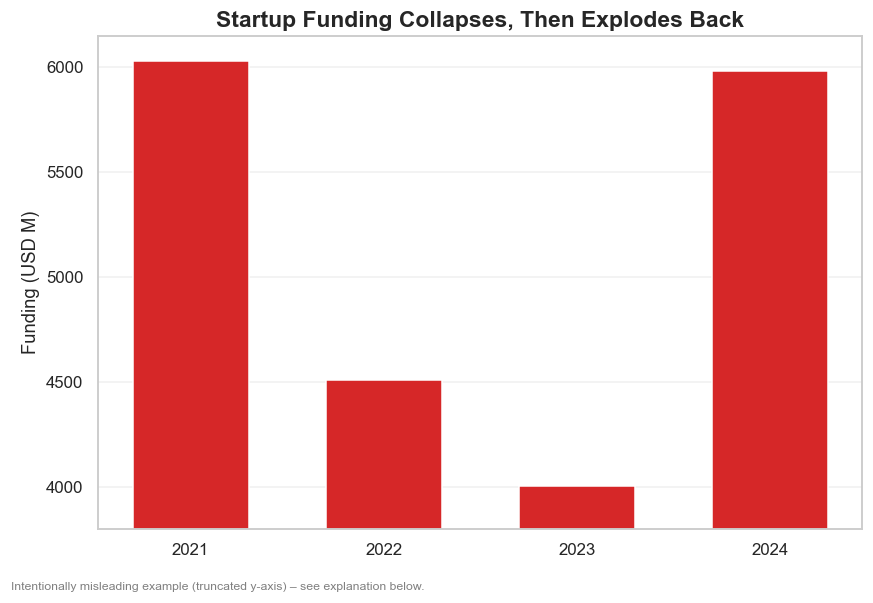

In [47]:
# Full years from the second dataset (2025 is partial, so it is excluded)
mis = yearly.loc[2021:2024, "Funding_M"]
Y_START = 3800            # deliberately NOT zero

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.bar(mis.index.astype(str), mis.values, color="#d62728", width=0.6)
ax.set_ylim(Y_START, mis.max() * 1.02)
ax.set_ylabel("Funding (USD M)")
ax.set_title("Startup Funding Collapses, Then Explodes Back", fontsize=15, fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", visible=False)
fig.text(0.01, 0.01, "Intentionally misleading example (truncated y-axis) – see explanation below.",
         fontsize=8, color="gray")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

### How this chart misleads

- **The truncated axis breaks the link between bar height and value.** Bars are read by their length, so a bar that is twice as tall is assumed to represent twice the funding. Starting the axis at USD 3,800M removes the first 3,800 units of every bar, so the **2023 bar looks about 9% as tall as 2021**, although 2023 funding is really about **66%** of 2021 funding.
- **Small changes look dramatic.** The 2024 bar looks roughly **11 times** taller than the 2023 bar, although funding rose by only about **49%**. The table below measures this exaggeration with the *lie factor* (the size of the effect shown in the graphic divided by the size of the effect in the data).
- **The headline and colour push a conclusion the data does not support.** Funding fell by about 34% between 2021 and 2023 and then partly recovered. That is a slowdown and a rebound, not a collapse and an explosion.
- **Hidden context.** Showing only 2021–2024 hides that 2017 funding (about USD 10.4B) was higher than any year in this window, and the missing value labels make it harder to check the picture against the real numbers.

## 20. Corrected Version – Ethical Redesign

The same four numbers are redrawn using ethical visualization principles:

1. **Zero baseline** – bar lengths are proportional to funding.
2. **Neutral, descriptive title** – it says what is shown and does not interpret it.
3. **Value labels** – every bar shows its exact amount.
4. **Year-on-year change stated as numbers** – the size of each change is given in percent, so the viewer does not need to judge it by eye.
5. **Disclosure** – the footnote explains the axis and why 2025 is excluded.

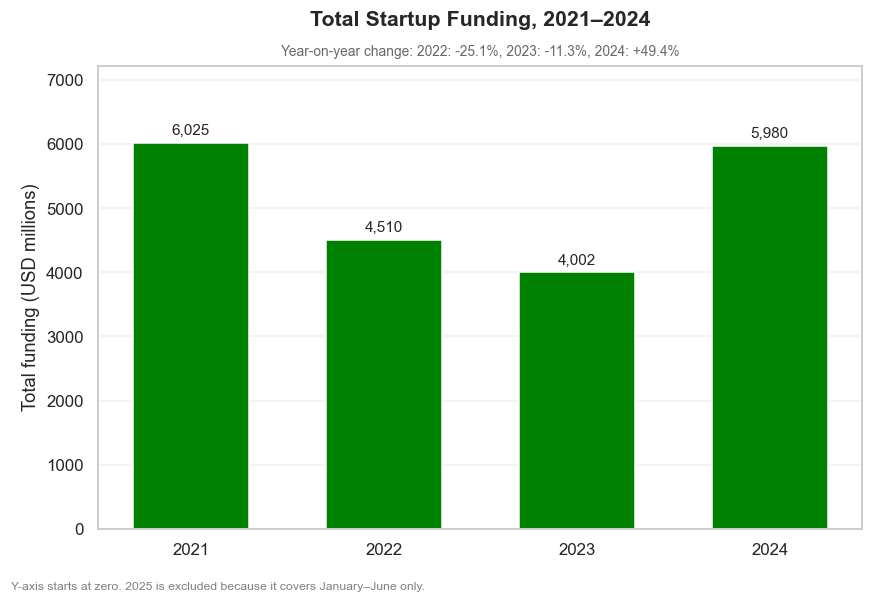

In [48]:
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(mis.index.astype(str), mis.values, color="green", width=0.6)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in mis.values], padding=3, fontsize=10)
ax.set_ylim(0, mis.max() * 1.2)
ax.set_ylabel("Total funding (USD millions)")

yoy = mis.pct_change().dropna() * 100
subtitle = "Year-on-year change: " + ", ".join(f"{y}: {v:+.1f}%" for y, v in yoy.items())
ax.set_title("Total Startup Funding, 2021–2024", fontsize=14, fontweight="bold", pad=26)
ax.text(0.5, 1.02, subtitle, transform=ax.transAxes, ha="center", fontsize=9, color="dimgray")
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", visible=False)
fig.text(0.01, 0.01, "Y-axis starts at zero. 2025 is excluded because it covers January–June only.",
         fontsize=8, color="gray")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

In [49]:
# How much does the truncated chart exaggerate? (lie factor = effect shown / effect in data)
cmp = pd.DataFrame({"Funding (USD M)": mis})
cmp["Actual, % of 2021"] = cmp["Funding (USD M)"] / cmp["Funding (USD M)"].iloc[0] * 100
cmp["Bar height shown (USD M above axis start)"] = cmp["Funding (USD M)"] - Y_START
cmp["Bar height shown, % of 2021 bar"] = (cmp["Bar height shown (USD M above axis start)"]
                                          / cmp["Bar height shown (USD M above axis start)"].iloc[0] * 100)
display(cmp.round(1))

rows = []
for a, b in [(2021, 2023), (2023, 2024)]:
    actual = (mis[b] / mis[a] - 1) * 100
    shown = ((mis[b] - Y_START) / (mis[a] - Y_START) - 1) * 100
    rows.append({"Period": f"{a} → {b}", "Actual change (%)": actual,
                 "Change shown by bars (%)": shown, "Lie factor": abs(shown / actual)})
display(pd.DataFrame(rows).set_index("Period").round(1))

,Funding (USD M),"Actual, % of 2021",Bar height shown (USD M above axis start),"Bar height shown, % of 2021 bar"
Year,,,,
2021,6024.9,100.0,2224.9,100.0
2022,4509.7,74.9,709.7,31.9
2023,4002.0,66.4,202.0,9.1
2024,5979.8,99.3,2179.8,98.0


,Actual change (%),Change shown by bars (%),Lie factor
Period,,,
2021 → 2023,-33.6,-90.9,2.7
2023 → 2024,49.4,979.2,19.8


### How the redesign fixes it

- With a **zero baseline**, the 2023 bar is about two-thirds the height of the 2021 bar and the 2024 bar is about 1.5 times the 2023 bar, which matches the real changes (-33.6% and +49.4%). The lie factor of the redesigned chart is **1**, because the visual change equals the real change.
- The **neutral title and labelled values** let viewers check the picture against the numbers and reach their own conclusion.
- The data tells a more modest story: a **slowdown after 2021, a low in 2023, and a rebound in 2024**, with 2024 still below the 2021 level.
- For the full context, **Visualization 1** shows all years from 2015 to 2025 with a zero baseline, the dataset boundary and the partial-year marker.

## 21. Ethical Reflection

Every chart in this analysis is a set of choices: which years to show, where the axis starts, what the title says, and which records are included. Each choice can help or distort the viewer's understanding, even when no number is wrong. The misleading chart above uses only true data and still creates a false impression, which shows why visualization needs ethical standards as well as technical ones.

**Principles followed in this notebook:**
- **Honest scales.** Bar and area charts start at zero. Where a logarithmic scale was needed (the boxplot, the scatter plot and the heatmap colours), it is stated in the axis label or colour bar, because a log scale also changes how differences look.
- **Undisclosed values are not zeros.** About 24% of deals have no disclosed amount. They are excluded from money charts and counted in deal-count charts, and the report states this.
- **Disclosing data limitations.** The two source datasets use different labels, and the second looks like a sample. Charts mark the 2020 boundary, restrict sector comparisons to industries present in both datasets, and the insights warn when a pattern may come from the data source.
- **Correcting and disclosing errors.** A rupee amount recorded in the USD column (Rapido, 2019) was corrected and documented, not left in or silently removed.
- **Partial periods are labelled.** 2025 is marked as January–June only.
- **Neutral titles and labelled values** so viewers can verify what they see.

## 22. Conclusion

This case study combined two public datasets to examine Indian startup funding from 2015 to 2025, using Matplotlib, Seaborn, Plotly and Power BI. The main findings are:

- **Funding is volatile, not steadily growing.** Total funding peaked at USD 10,429M in 2017, fell about 33.6% from 2021 to 2023, then rebounded in 2024. 2025 (January–June) already stands at USD 2,813M, about 47% of the 2024 total.
- **The sector mix has shifted.** E-commerce lost the most share (-72.3 percentage points) between 2015–2017 and 2023–2025, while FoodTech gained the most (+25.3 pp), followed by EdTech.
- **Funding is geographically concentrated.** Bengaluru (29.6%), Delhi NCR (28.7%) and Mumbai (12.5%) together hold 70.8% of disclosed funding.
- **Deal size rises sharply with stage.** The median grows from USD 0.02M at Angel to USD 0.30M at Seed, USD 3.56M at Series A, USD 21.3M at Series B and USD 65.9M at Series C.
- **A few investors dominate activity.** Sequoia Capital India (188 deals), Tiger Global Management (185) and Accel (155) lead, but the ranking leans heavily on the second dataset.
- **Chart design changes the story.** The truncated-axis chart made a 49% rise in 2024 look about 11 times taller than 2023. The corrected version removes this distortion.

**Limitations:** about 24% of deals have no disclosed amount, and the second dataset appears to be a sample with different labels. Cross-period comparisons around 2020 should therefore be read as indicative, not exact.

## 23. Recommendations

**For investors and analysts**
1. Judge funding trends using both total amount and deal count. Large single rounds can distort yearly totals.
2. Use the median deal size by stage, not the average, because a few very large deals pull averages up.
3. Look beyond the three leading cities. Tier-2 cities show a higher share of deals after 2020, though the evidence is weak.

**For founders and policymakers**
4. Funding has shifted from e-commerce towards FoodTech, EdTech and HealthTech, so these sectors are the more active areas to watch.
5. Funding concentration in a few cities suggests room for programmes that support startups elsewhere.

**For data communication and future work**
6. Always start bar charts at zero, label the axes and state partial periods (as with 2025).
7. Repeat the analysis with a complete, consistently labelled dataset for 2020–2025 to confirm the sector, city and investor patterns.
8. Extend the work with funding-per-deal growth rates or a forecast, once data quality allows.

In [50]:
# ---------- Export cleaned dataset (for Power BI and submission) ----------
import os
os.makedirs("outputs", exist_ok=True)

clean = df.copy()
clean["Deal_ID"] = range(1, len(clean) + 1)

# Keep the analysis columns, plus the original raw labels for traceability
cols = ["Deal_ID", "Startup", "Date", "Year", "Month",
        "Industry", "Industry_Clean", "SubVertical",
        "City", "City_Clean", "Investors",
        "InvestmentType", "Stage",
        "InvestmentAmount_USD", "Amount_M", "Data Source"]
clean[cols].to_csv("outputs/startup_funding_cleaned.csv", index=False)

print("Saved:", clean.shape[0], "rows,", len(cols), "columns")

Saved: 4144 rows, 16 columns
